# Hard Disk Drive Failure Analysis and Prediction
**Student Name:** Md Hasan  
**Student ID:** 0432320005101135  

This notebook has **one single code cell**. Click the cell and press **Shift + Enter** once to run everything.

It downloads a public HDD dataset sample, preprocesses it, trains an XGBoost classifier, prints evaluation metrics, shows a confusion matrix and feature-importance plot, then saves the model and CSV. The PDF describes Meta's internal dataset, which is not included; this is an educational experiment using a public sample.

Student: Md Hasan
ID: 0432320005101135
Libraries imported successfully.
Dataset shape: (999, 38)


,date,serial_number,model,failure,vault_id,pod_id,pod_slot_num,smart_1_normalized,smart_1_raw,smart_2_normalized,...,smart_192_raw,smart_193_normalized,smart_193_raw,smart_194_normalized,smart_194_raw,smart_196_normalized,smart_196_raw,smart_197_raw,smart_198_raw,smart_199_raw
0,2024-01-01,5PGXGMYE,HGST HUH721212ALE604,0,1056,6,48.0,100.0,0.0,132.0,...,951.0,100.0,951.0,171.0,35.0,100.0,0.0,0.0,0.0,0.0
1,2024-01-01,5PH8YR9F,HGST HUH721212ALE604,0,1056,6,24.0,100.0,0.0,133.0,...,1114.0,100.0,1114.0,187.0,32.0,100.0,0.0,0.0,0.0,0.0
2,2024-01-01,5PHAB41D,HGST HUH721212ALE604,0,1056,6,0.0,100.0,0.0,132.0,...,1076.0,100.0,1076.0,206.0,29.0,100.0,0.0,0.0,0.0,0.0
3,2024-01-01,5PHGLUKD,HGST HUH721212ALE604,0,1056,6,49.0,100.0,0.0,130.0,...,1051.0,100.0,1051.0,176.0,34.0,100.0,0.0,0.0,0.0,0.0
4,2024-01-01,5PHH7R6D,HGST HUH721212ALE604,0,1056,6,1.0,100.0,0.0,132.0,...,1055.0,100.0,1055.0,206.0,29.0,100.0,0.0,1.0,0.0,0.0



Columns:
['date', 'serial_number', 'model', 'failure', 'vault_id', 'pod_id', 'pod_slot_num', 'smart_1_normalized', 'smart_1_raw', 'smart_2_normalized', 'smart_2_raw', 'smart_3_normalized', 'smart_3_raw', 'smart_4_raw', 'smart_5_normalized', 'smart_5_raw', 'smart_7_normalized', 'smart_7_raw', 'smart_8_normalized', 'smart_8_raw', 'smart_9_normalized', 'smart_9_raw', 'smart_10_normalized', 'smart_10_raw', 'smart_12_raw', 'smart_22_normalized', 'smart_22_raw', 'smart_192_normalized', 'smart_192_raw', 'smart_193_normalized', 'smart_193_raw', 'smart_194_normalized', 'smart_194_raw', 'smart_196_normalized', 'smart_196_raw', 'smart_197_raw', 'smart_198_raw', 'smart_199_raw']
Target column: failure
failure
0    999
Name: count, dtype: int64
Usable rows: 999
Numeric features: 23
Class counts:
failure
0    999
Name: count, dtype: int64
Accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       250

    accuracy  

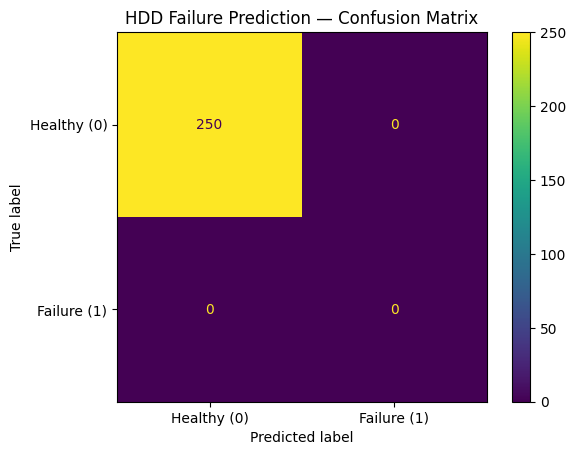

,importance
vault_id,0.0
pod_id,0.0
pod_slot_num,0.0
smart_2_normalized,0.0
smart_2_raw,0.0
smart_3_normalized,0.0
smart_3_raw,0.0
smart_4_raw,0.0
smart_5_raw,0.0
smart_8_normalized,0.0


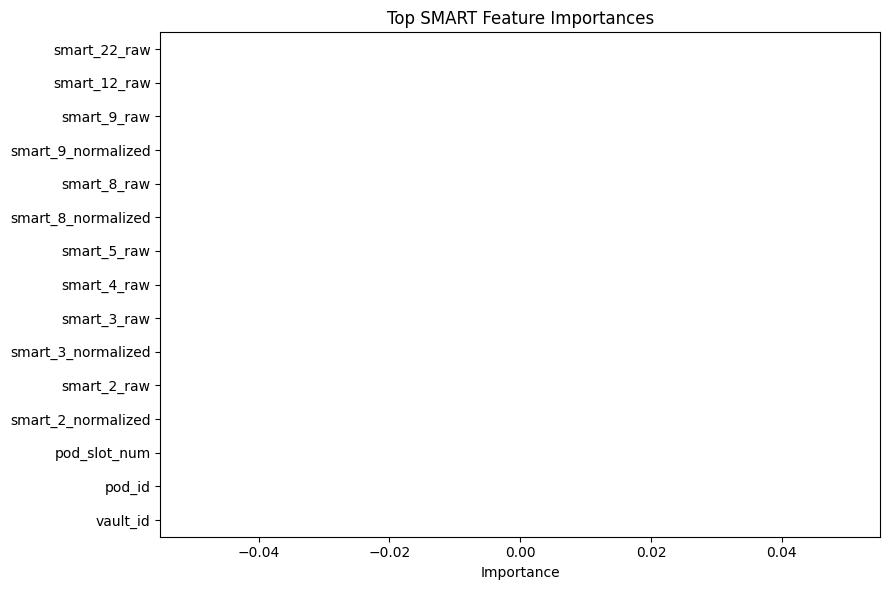

Saved model: /content/md_hasan_hdd_failure_model.pkl
Saved sample data: /content/md_hasan_hdd_sample_used.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ==============================================================================
# SECTION 1
# ----------------------------------------------------------------------
!pip -q install xgboost scikit-learn pandas matplotlib seaborn requests

import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from xgboost import XGBClassifier

RANDOM_STATE = 35
np.random.seed(RANDOM_STATE)

print("Student: Md Hasan")
print("ID: 0432320005101135")
print("Libraries imported successfully.")

# SECTION 2
# ----------------------------------------------------------------------
# Using the GitHub LFS media URL to download the actual CSV content instead of the pointer file
CSV_URL = "https://media.githubusercontent.com/media/tang-le123/hard-drive-failure-dataset/main/sample_HGST_HUH721212ALE604.csv"
CSV_PATH = "/content/hdd_sample.csv"

response = requests.get(CSV_URL, timeout=60)
response.raise_for_status()
with open(CSV_PATH, "wb") as f:
    f.write(response.content)

df = pd.read_csv(CSV_PATH, low_memory=False)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

# SECTION 3
# ----------------------------------------------------------------------
# Identify a target/label column from common names
target_candidates = [
    "failure", "Failure", "is_failure", "failed", "label",
    "failure_label", "health", "status", "target"
]
target_col = next((c for c in target_candidates if c in df.columns), None)

if target_col is None:
    print("Could not automatically identify a target column.")
    print("Inspect the column list above and set TARGET_COL manually.")
    print("Example: TARGET_COL = 'failure'")
    raise ValueError("Please set TARGET_COL to the dataset's actual failure/health label column.")
else:
    TARGET_COL = target_col

print("Target column:", TARGET_COL)
print(df[TARGET_COL].value_counts(dropna=False).head(20))

# Convert target to binary when it is already encoded as 0/1 or equivalent text
work = df.copy()
y_raw = work[TARGET_COL]

if y_raw.dtype == "object":
    normalized = y_raw.astype(str).str.strip().str.lower()
    mapping = {
        "0": 0, "1": 1, "healthy": 0, "ok": 0, "normal": 0,
        "failed": 1, "failure": 1, "unhealthy": 1, "faulty": 1,
        "true": 1, "false": 0
    }
    y = normalized.map(mapping)
else:
    y = pd.to_numeric(y_raw, errors="coerce")

valid = y.isin([0, 1])
work = work.loc[valid].copy()
y = y.loc[valid].astype(int)

# Remove target and identifier/date/text columns from features
drop_cols = [TARGET_COL]
for c in work.columns:
    c_low = c.lower()
    if c == TARGET_COL:
        continue
    if any(term in c_low for term in ["serial", "date", "model", "firmware", "capacity", "device", "hostname", "ip"]):
        drop_cols.append(c)

X = work.drop(columns=list(set(drop_cols)), errors="ignore")
X = X.apply(pd.to_numeric, errors="coerce")
# Remove completely empty or constant columns
X = X.dropna(axis=1, how="all")
X = X.loc[:, X.nunique(dropna=True) > 1]

print("Usable rows:", len(X))
print("Numeric features:", X.shape[1])
print("Class counts:")
print(y.value_counts())

# SECTION 4
# ----------------------------------------------------------------------
if X.shape[1] == 0:
    raise ValueError("No numeric feature columns were found. Check the dataset and feature selection.")

# Stratify only when both classes have at least two samples
stratify_y = y if y.nunique() == 2 and y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=stratify_y
)

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

# Handle class imbalance using balanced sample weights
class_counts = y_train.value_counts()
weights = y_train.map(lambda v: len(y_train) / (2 * class_counts[v]) if v in class_counts else 1.0)

model = XGBClassifier(
    n_estimators=120,
    max_depth=4,
    learning_rate=0.08,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="logloss",
    random_state=RANDOM_STATE
)
model.fit(X_train_imp, y_train, sample_weight=weights)

pred = model.predict(X_test_imp)
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("\nClassification report:")
print(classification_report(y_test, pred, zero_division=0))

# SECTION 5
# ----------------------------------------------------------------------
cm = confusion_matrix(y_test, pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Healthy (0)", "Failure (1)"])
disp.plot(values_format="d")
plt.title("HDD Failure Prediction — Confusion Matrix")
plt.show()

# SECTION 6
# ----------------------------------------------------------------------
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
display(importance.to_frame("importance"))
importance.sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Top SMART Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# SECTION 7
# ----------------------------------------------------------------------
import joblib
joblib.dump({"model": model, "imputer": imputer, "feature_columns": list(X.columns)}, "/content/md_hasan_hdd_failure_model.pkl")
work.to_csv("/content/md_hasan_hdd_sample_used.csv", index=False)
print("Saved model: /content/md_hasan_hdd_failure_model.pkl")
print("Saved sample data: /content/md_hasan_hdd_sample_used.csv")

# Download outputs in Google Colab
try:
    from google.colab import files
    files.download("/content/md_hasan_hdd_failure_model.pkl")
    files.download("/content/md_hasan_hdd_sample_used.csv")
except Exception:
    print("Not running in Google Colab; files are saved in the current directory.")